In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import warnings
warnings.filterwarnings("ignore")
sns.set(style="whitegrid")

In [10]:
df=pd.read_csv("AIML Dataset.csv")

In [8]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            object 
 2   amount          float64
 3   nameOrig        object 
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        object 
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 534.0+ MB


In [11]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='object')

In [12]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [144]:
df["isFlaggedFraud"].value_counts()

isFlaggedFraud
0    6362604
1         16
Name: count, dtype: int64

In [14]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [15]:
df.isnull().sum().sum()

np.int64(0)

In [16]:
df.shape

(6362620, 11)

In [17]:
df.shape[0]

6362620

In [18]:
round((df["isFraud"].value_counts()[1]/df.shape[0])*100,2)

np.float64(0.13)

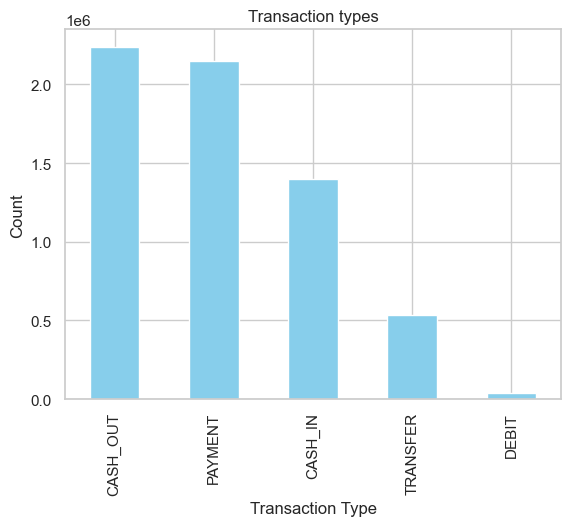

In [19]:
df["type"].value_counts().plot(kind="bar",title="Transaction types",color="skyblue")
plt.xlabel("Transaction Type")
plt.ylabel("Count")
plt.show()

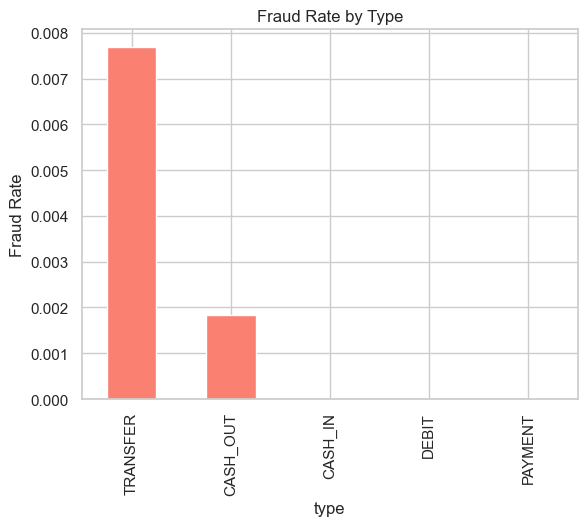

In [20]:
fraud_by_type=df.groupby("type")["isFraud"].mean().sort_values(ascending=False)
fraud_by_type.plot(kind="bar",title="Fraud Rate by Type",color="salmon")
plt.ylabel("Fraud Rate")
plt.show()

In [21]:
df["amount"].describe().astype(int)

count     6362620
mean       179861
std        603858
min             0
25%         13389
50%         74871
75%        208721
max      92445516
Name: amount, dtype: int64

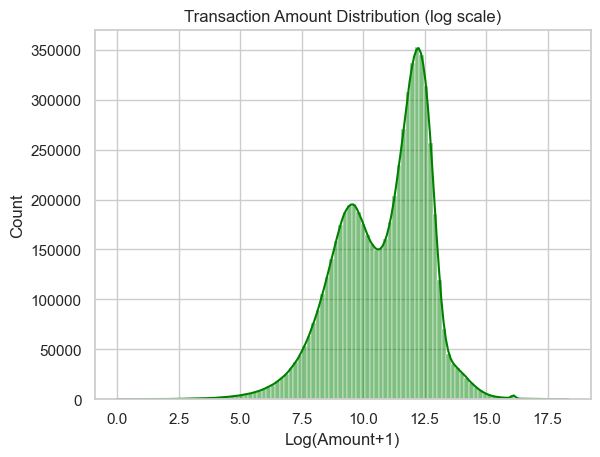

In [22]:
sns.histplot(np.log1p(df["amount"]),bins=100,kde= True, color = "green")
plt.title("Transaction Amount Distribution (log scale)")
plt.xlabel("Log(Amount+1)")
plt.show()

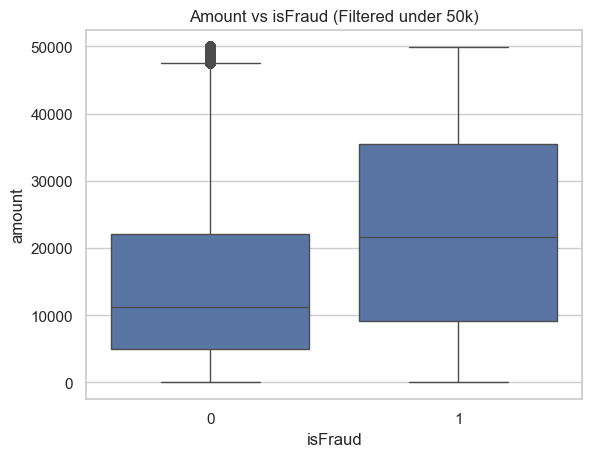

In [23]:
sns.boxplot(data=df[df["amount"]<50000],x="isFraud",y="amount")
plt.title("Amount vs isFraud (Filtered under 50k)")
plt.show()

In [24]:
df["balanceDiffOrig"]=df["oldbalanceOrg"]-df["newbalanceOrig"]
df["balancedDiffDest"]=df["newbalanceDest"]-df["oldbalanceDest"]

In [25]:
(df["balanceDiffOrig"]<0).sum()

np.int64(1399253)

In [26]:
(df["balancedDiffDest"]<0).sum()

np.int64(1238864)

In [27]:
df.head(2)

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balancedDiffDest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0


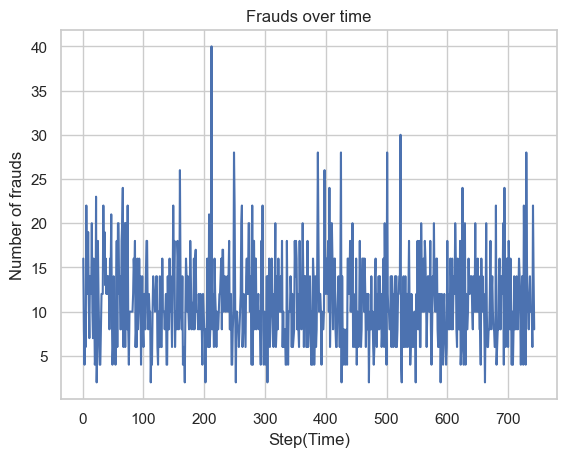

In [28]:
frauds_per_step=df[df["isFraud"]==1]["step"].value_counts().sort_index()
plt.plot(frauds_per_step.index , frauds_per_step.values, label="Frauds per Step")
plt.xlabel("Step(Time)")
plt.ylabel("Number of frauds")
plt.title("Frauds over time")
plt.grid(True)
plt.show()

In [29]:
df.drop(columns="step",inplace=True)

In [30]:
df.head(10)

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balancedDiffDest
0,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.00,0,0,9839.64,0.00
1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.00,0,0,1864.28,0.00
2,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.00,1,0,181.00,0.00
3,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.00,1,0,181.00,-21182.00
4,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.00,0,0,11668.14,0.00
5,PAYMENT,7817.71,C90045638,53860.00,46042.29,M573487274,0.0,0.00,0,0,7817.71,0.00
6,PAYMENT,7107.77,C154988899,183195.00,176087.23,M408069119,0.0,0.00,0,0,7107.77,0.00
7,PAYMENT,7861.64,C1912850431,176087.23,168225.59,M633326333,0.0,0.00,0,0,7861.64,0.00
8,PAYMENT,4024.36,C1265012928,2671.00,0.00,M1176932104,0.0,0.00,0,0,2671.00,0.00
9,DEBIT,5337.77,C712410124,41720.00,36382.23,C195600860,41898.0,40348.79,0,0,5337.77,-1549.21


In [31]:
top_senders=df["nameOrig"].value_counts().head(10)

In [32]:
top_senders

nameOrig
C1677795071    3
C1999539787    3
C724452879     3
C1976208114    3
C400299098     3
C1784010646    3
C1530544995    3
C1065307291    3
C545315117     3
C1902386530    3
Name: count, dtype: int64

In [33]:
top_receivers=df["nameDest"].value_counts().head(10)

In [34]:
top_receivers

nameDest
C1286084959    113
C985934102     109
C665576141     105
C2083562754    102
C248609774     101
C1590550415    101
C1789550256     99
C451111351      99
C1360767589     98
C1023714065     97
Name: count, dtype: int64

In [35]:
fraud_users=df[df["isFraud"]==1]["nameOrig"].value_counts().head(10)

In [36]:
fraud_users

nameOrig
C1280323807    1
C1305486145    1
C840083671     1
C1420196421    1
C2101527076    1
C1039979813    1
C2089752665    1
C1614818636    1
C40604503      1
C1970706589    1
Name: count, dtype: int64

In [38]:
fraud_types=df[df["type"].isin(["TRANSFER","CASH_OUT"])]

In [39]:
fraud_types["type"].value_counts()

type
CASH_OUT    2237500
TRANSFER     532909
Name: count, dtype: int64

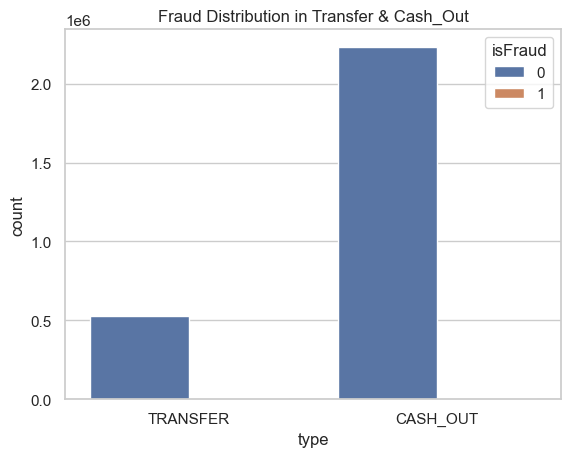

In [41]:
sns.countplot(data=fraud_types,x="type",hue="isFraud")
plt.title("Fraud Distribution in Transfer & Cash_Out")
plt.show()

In [43]:
corr=df[["amount","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest","isFraud"]].corr()

In [44]:
corr

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud
amount,1.000000,-0.002762,-0.007861,0.294137,0.459304,0.076688
oldbalanceOrg,-0.002762,1.000000,0.998803,0.066243,0.042029,0.010154
newbalanceOrig,-0.007861,0.998803,1.000000,0.067812,0.041837,-0.008148
oldbalanceDest,0.294137,0.066243,0.067812,1.000000,0.976569,-0.005885
newbalanceDest,0.459304,0.042029,0.041837,0.976569,1.000000,0.000535
isFraud,0.076688,0.010154,-0.008148,-0.005885,0.000535,1.000000


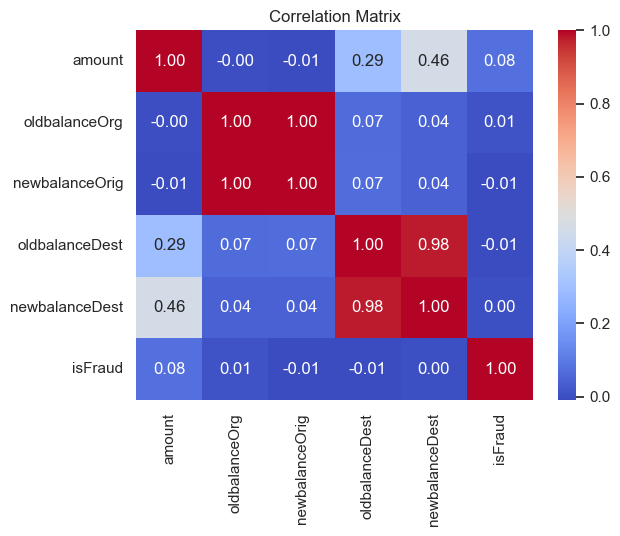

In [45]:
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

In [46]:
zero_after_transfer=df[(df["oldbalanceOrg"]>0) & (df["newbalanceOrig"]==0) & (df["type"].isin(["TRANSFER","CASH_OUT"]))]

In [47]:
len(zero_after_transfer)

1188074

In [48]:
zero_after_transfer.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balancedDiffDest
2,TRANSFER,181.00,C1305486145,181.0,0.0,C553264065,0.0,0.00,1,0,181.0,0.00
3,CASH_OUT,181.00,C840083671,181.0,0.0,C38997010,21182.0,0.00,1,0,181.0,-21182.00
15,CASH_OUT,229133.94,C905080434,15325.0,0.0,C476402209,5083.0,51513.44,0,0,15325.0,46430.44
19,TRANSFER,215310.30,C1670993182,705.0,0.0,C1100439041,22425.0,0.00,0,0,705.0,-22425.00
24,TRANSFER,311685.89,C1984094095,10835.0,0.0,C932583850,6267.0,2719172.89,0,0,10835.0,2712905.89


In [49]:
df["isFraud"].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [54]:
df.head()

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balanceDiffOrig,balancedDiffDest
0,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [55]:
df_model=df.drop(["nameOrig","nameDest","isFlaggedFraud"],axis=1)

In [56]:
df_model.head()

,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,balanceDiffOrig,balancedDiffDest
0,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0
1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0
2,TRANSFER,181.00,181.0,0.00,0.0,0.0,1,181.00,0.0
3,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,1,181.00,-21182.0
4,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0


In [64]:
categorical=["type"]
numeric=["amount","oldbalanceOrg","newbalanceOrig","oldbalanceDest","newbalanceDest"]

In [65]:
y=df_model["isFraud"]
X=df_model.drop("isFraud",axis=1)

In [66]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,stratify=y)

In [67]:
preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numeric),("cat",OneHotEncoder(drop="first"),categorical)
    ],
    remainder="drop"
)

In [68]:
pipeline=Pipeline([("prep",preprocessor),("clf",LogisticRegression(class_weight="balanced",max_iter=1000))
                  ])

In [69]:
pipeline.fit(X_train,y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amount', 'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['type'])])),
                ('clf',
                 LogisticRegression(class_weight='balanced', max_iter=1000))])

In [71]:
y_pred=pipeline.predict(X_test)

In [72]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1906322
           1       0.02      0.94      0.04      2464

    accuracy                           0.95   1908786
   macro avg       0.51      0.94      0.51   1908786
weighted avg       1.00      0.95      0.97   1908786



In [74]:
confusion_matrix(y_test,y_pred)

array([[1804702,  101620],
       [    151,    2313]])

In [75]:
pipeline.score(X_test,y_test)

0.946682865444319

In [112]:
from sklearn.metrics import roc_auc_score
y_prob = pipeline.predict_proba(X_test)[:,1]
roc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", roc)

ROC-AUC Score: 0.9892632737451845


In [136]:
y_prob = pipeline.predict_proba(X_test)[:, 1]
threshold = 0.7
y_pred = (y_prob >= threshold).astype(int)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.97      0.99   1906322
           1       0.04      0.88      0.08      2464

    accuracy                           0.97   1908786
   macro avg       0.52      0.92      0.53   1908786
weighted avg       1.00      0.97      0.99   1908786



In [135]:
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)
f1 = 2 * precision * recall / (precision + recall + 1e-10)
best = np.argmax(f1)
print("Best Threshold:", thresholds[best])

Best Threshold: 0.9998603776434315


In [137]:
y_prob = pipeline.predict_proba(X_test)[:, 1]
threshold = 0.9998603776434315
y_pred = (y_prob >= threshold).astype(int)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906322
           1       0.75      0.48      0.58      2464

    accuracy                           1.00   1908786
   macro avg       0.87      0.74      0.79   1908786
weighted avg       1.00      1.00      1.00   1908786



In [138]:
from sklearn.metrics import roc_auc_score
y_prob = pipeline.predict_proba(X_test)[:,1]
roc = roc_auc_score(y_test, y_prob)
print("ROC-AUC Score:", roc)

ROC-AUC Score: 0.9892632737451845


In [79]:
from sklearn.tree import DecisionTreeClassifier

In [80]:
dt_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

In [81]:
dt_pipeline.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amount', 'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['type'])])),
                ('clf',
                 DecisionTreeClassifier(class_weight='balanced',
                                        random_state=42))])

In [82]:
y_pred_dt = dt_pipeline.predict(X_test)

In [83]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906322
           1       0.91      0.86      0.88      2464

    accuracy                           1.00   1908786
   macro avg       0.95      0.93      0.94   1908786
weighted avg       1.00      1.00      1.00   1908786



In [114]:
from sklearn.metrics import roc_auc_score
prob = dt_pipeline.predict_proba(X_test)[:,1]
print(roc_auc_score(y_test, prob))

0.9301365778858826


In [85]:
print(dt_pipeline.score(X_train, y_train))

1.0


In [86]:
from sklearn.ensemble import RandomForestClassifier

In [91]:
rf_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", RandomForestClassifier(
        random_state=42,
        class_weight="balanced",
        n_estimators=50,
        max_depth=10,
        min_samples_split=5,
        n_jobs=-1
    ))
])

In [92]:
rf_pipeline.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amount', 'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['type'])])),
                ('clf',
                 RandomForestClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_split=5, n_estimators=50,
                                        n_jobs=-1, random_state=42))])

In [93]:
y_pred_rf = rf_pipeline.predict(X_test)

In [94]:
from sklearn.metrics import classification_report
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99   1906322
           1       0.09      0.99      0.17      2464

    accuracy                           0.99   1908786
   macro avg       0.55      0.99      0.58   1908786
weighted avg       1.00      0.99      0.99   1908786



In [95]:
from sklearn.metrics import roc_auc_score

prob = rf_pipeline.predict_proba(X_test)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, prob))

ROC-AUC: 0.9985544177044632


In [115]:
from sklearn.metrics import classification_report
prob = rf_pipeline.predict_proba(X_test)[:,1]
for threshold in [0.5, 0.6, 0.7, 0.8, 0.9]:
    print(f"\nThreshold: {threshold}")
    y_pred_rf = (prob >= threshold).astype(int)
    print(classification_report(y_test, y_pred_rf))


Threshold: 0.5
              precision    recall  f1-score   support

           0       1.00      0.99      0.99   1906322
           1       0.09      0.99      0.17      2464

    accuracy                           0.99   1908786
   macro avg       0.55      0.99      0.58   1908786
weighted avg       1.00      0.99      0.99   1908786


Threshold: 0.6
              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1906322
           1       0.12      0.99      0.21      2464

    accuracy                           0.99   1908786
   macro avg       0.56      0.99      0.60   1908786
weighted avg       1.00      0.99      0.99   1908786


Threshold: 0.7
              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1906322
           1       0.18      0.97      0.31      2464

    accuracy                           0.99   1908786
   macro avg       0.59      0.98      0.65   1908786
weighted avg       1.00   

In [116]:
from sklearn.metrics import precision_recall_curve
import numpy as np
prob = rf_pipeline.predict_proba(X_test)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_test, prob)
f1 = 2 * (precision * recall) / (precision + recall + 1e-10)
best_index = np.argmax(f1)
print("Best Threshold:", thresholds[best_index])
print("Best F1-score:", f1[best_index])
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])

Best Threshold: 0.9350647999568751
Best F1-score: 0.8476517754376589
Precision: 0.97317201472909
Recall: 0.7508116883116883


In [142]:
rf_pipeline.score(X_test,y_test)*100

98.71740467501333

In [117]:
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
scale_pos_weight = neg / pos
print("Scale Pos Weight:", scale_pos_weight)

Scale Pos Weight: 773.7145590537485


In [100]:
from xgboost import XGBClassifier

In [101]:
xgb_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", XGBClassifier(
        random_state=42,
        n_estimators=100,
        learning_rate=0.1,
        max_depth=6,
        scale_pos_weight=scale_pos_weight,
        eval_metric="logloss",
        tree_method="hist",
        n_jobs=-1
    ))
])

In [102]:
xgb_pipeline.fit(X_train, y_train)

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['amount', 'oldbalanceOrg',
                                                   'newbalanceOrig',
                                                   'oldbalanceDest',
                                                   'newbalanceDest']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['type'])])),
                ('clf',
                 XGBClassifier(base_score=None, booster=None, callbacks=None,
                               colsample_bylevel=None, colsample_bynode=None,
                               colsample_bytree=None, device=None...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=6, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [103]:
from sklearn.metrics import classification_report
y_pred_xgb = xgb_pipeline.predict(X_test)
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      0.99      1.00   1906322
           1       0.20      1.00      0.33      2464

    accuracy                           0.99   1908786
   macro avg       0.60      1.00      0.66   1908786
weighted avg       1.00      0.99      1.00   1908786



In [125]:
from sklearn.metrics import roc_auc_score
xgb_prob = xgb_pipeline.predict_proba(X_test)[:,1]
print("ROC-AUC:", roc_auc_score(y_test, xgb_prob))

ROC-AUC: 0.9992905538346658


In [118]:
from sklearn.metrics import precision_recall_curve
import numpy as np
xgb_prob = xgb_pipeline.predict_proba(X_test)[:,1]
precision, recall, thresholds = precision_recall_curve(y_test, xgb_prob)
f1 = 2 * precision * recall / (precision + recall + 1e-10)
best = np.argmax(f1)
print("Best Threshold:", thresholds[best])
print("Precision:", precision[best])
print("Recall:", recall[best])
print("F1-score:", f1[best])

Best Threshold: 0.98890823
Precision: 0.930635838150289
Recall: 0.7840909090909091
F1-score: 0.8511013215362683


In [126]:
best_threshold = thresholds[best]
y_pred_xgb = (xgb_prob >= best_threshold).astype(int)
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1906322
           1       0.93      0.78      0.85      2464

    accuracy                           1.00   1908786
   macro avg       0.97      0.89      0.93   1908786
weighted avg       1.00      1.00      1.00   1908786



In [139]:
import pandas as pd
comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "XGBoost"
    ],
    "Threshold": [
        "0.99986",
        "0.50 (Default)",
        "0.9351",
        "0.9889"
    ],
    "Precision": [
        0.75,
        0.91,
        0.9732,
        0.9306
    ],
    "Recall": [
        0.48,
        0.86,
        0.7508,
        0.7841
    ],
    "F1-score": [
        0.58,
        0.88,
        0.8477,
        0.8511
    ],
    "ROC-AUC": [
        0.9893,
        0.9301,
        0.9986,
        0.9993
    ]
})
comparison
comparison.style.highlight_max(
    subset=["Precision", "Recall", "F1-score", "ROC-AUC"],
    color="lightgreen"
)

,Model,Threshold,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.99986,0.750000,0.480000,0.580000,0.989300
1,Decision Tree,0.50 (Default),0.910000,0.860000,0.880000,0.930100
2,Random Forest,0.9351,0.973200,0.750800,0.847700,0.998600
3,XGBoost,0.9889,0.930600,0.784100,0.851100,0.999300


# Final Model Selection

Among the evaluated models, the Decision Tree achieved the highest F1-score (0.88), indicating the best balance between precision and recall on the test dataset. However, XGBoost achieved the highest ROC-AUC score (0.9993), demonstrating superior capability in distinguishing between fraudulent and legitimate transactions across different classification thresholds.

Although the Decision Tree showed a slightly higher F1-score, its perfect accuracy of 100% raises concerns about potential overfitting and limited generalization to unseen data. In contrast, XGBoost provided more reliable probability estimates and achieved strong classification performance, with a precision of 93.06% and recall of 78.41% after threshold optimization.

Furthermore, ensemble-based gradient boosting methods such as XGBoost generally provide better generalization, robustness, and stability compared to individual decision trees, making them more suitable for real-world fraud detection applications where handling unseen transaction patterns is crucial.

Therefore, XGBoost was selected as the final model due to its excellent discriminative ability, highest ROC-AUC score, strong precision-recall balance, and better expected generalization performance for fraud detection.


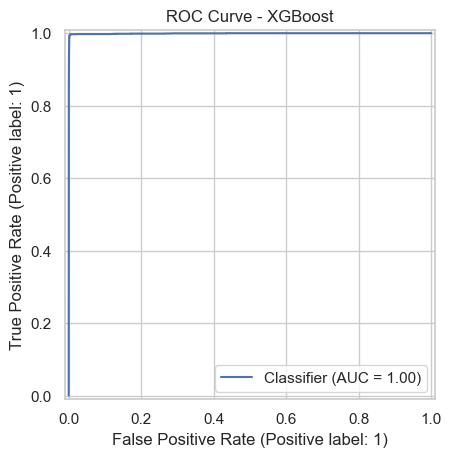

In [120]:
from sklearn.metrics import RocCurveDisplay
RocCurveDisplay.from_predictions(y_test, xgb_prob)
plt.title("ROC Curve - XGBoost")
plt.show()

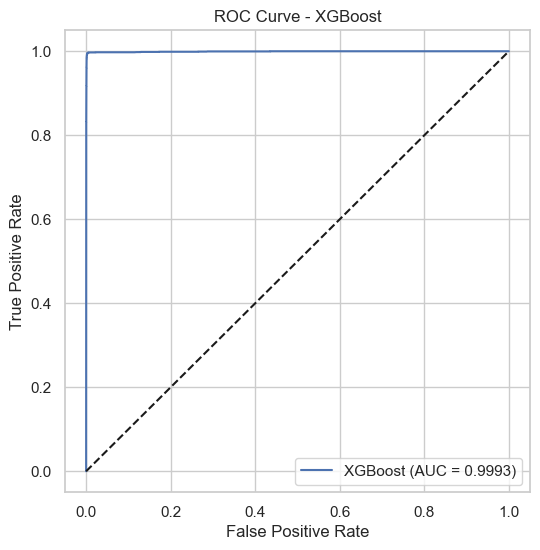

In [123]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt
fpr, tpr, _ = roc_curve(y_test, xgb_prob)
auc = roc_auc_score(y_test, xgb_prob)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"XGBoost (AUC = {auc:.4f})")
plt.plot([0,1],[0,1],'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost")
plt.legend()
plt.show()

In [121]:
feature_names = xgb_pipeline.named_steps["prep"].get_feature_names_out()
importance = xgb_pipeline.named_steps["clf"].feature_importances_
feat_imp = (
    pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })
    .sort_values("Importance", ascending=False)
)
feat_imp.head(15)

,Feature,Importance
2,num__newbalanceOrig,0.527581
7,cat__type_PAYMENT,0.199837
1,num__oldbalanceOrg,0.125395
0,num__amount,0.055487
8,cat__type_TRANSFER,0.042162
4,num__newbalanceDest,0.029186
5,cat__type_CASH_OUT,0.011928
3,num__oldbalanceDest,0.004559
6,cat__type_DEBIT,0.003865


In [122]:
print(numeric)

['amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest']


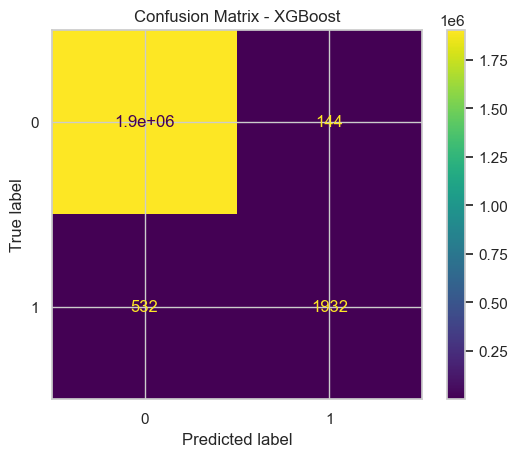

In [127]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_xgb)
plt.title("Confusion Matrix - XGBoost")
plt.show()

In [143]:
xgb_pipeline.score(X_test,y_test)

0.9946892946616331